In [12]:
from pathlib import Path

CARPETA = Path("tema12")
CARPETA.mkdir(exist_ok=True)

print("Los archivos de la práctica se guardarán en:", CARPETA)

Los archivos de la práctica se guardarán en: tema12


In [13]:
lugares = {
    "Mi vivienda en Pomacanchi": (-14.0359125, -71.570921875),
    "Universidad Nacional de San Antonio Abad del Cusco (UNSAAC)": (
        -13.521351, -71.9589345
    ),
    "Mi vivienda alquilada en Cusco": (
        -13.5465375, -71.867171875
    ),
    "Laguna Pomacanchi": (-14.02059, -71.52809),
}

for nombre, (lat, lon) in lugares.items():
    print(f"{nombre}: lat={lat}, lon={lon}")

Mi vivienda en Pomacanchi: lat=-14.0359125, lon=-71.570921875
Universidad Nacional de San Antonio Abad del Cusco (UNSAAC): lat=-13.521351, lon=-71.9589345
Mi vivienda alquilada en Cusco: lat=-13.5465375, lon=-71.867171875
Laguna Pomacanchi: lat=-14.02059, lon=-71.52809


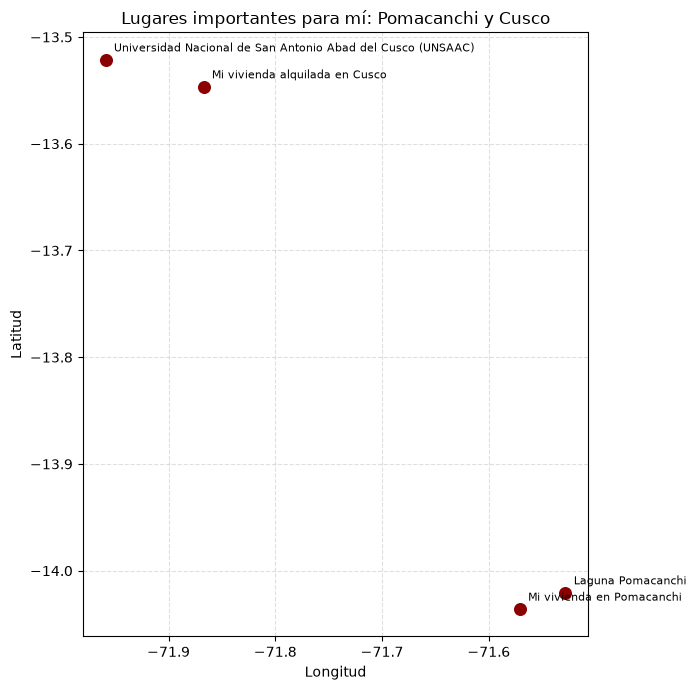

In [14]:
import matplotlib.pyplot as plt

nombres = list(lugares.keys())
lats = [coordenadas[0] for coordenadas in lugares.values()]
lons = [coordenadas[1] for coordenadas in lugares.values()]

fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(lons, lats, color="darkred", s=70)

for nombre, lon, lat in zip(nombres, lons, lats):
    ax.annotate(
        nombre,
        (lon, lat),
        textcoords="offset points",
        xytext=(6, 6),
        fontsize=8
    )

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Lugares importantes para mí: Pomacanchi y Cusco")
ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(CARPETA / "mapa_basico.png", dpi=300)
plt.show()

In [15]:
import math

def distancia_haversine(lat1, lon1, lat2, lon2):
    """Calcula en kilómetros la distancia entre dos coordenadas geográficas."""

    radio_tierra = 6371.0

    # Convertir las coordenadas de grados a radianes
    phi1 = math.radians(lat1)
    phi2 = math.radians(lat2)
    delta_phi = math.radians(lat2 - lat1)
    delta_lambda = math.radians(lon2 - lon1)

    # Aplicar la fórmula de Haversine
    a = (
        math.sin(delta_phi / 2) ** 2
        + math.cos(phi1) * math.cos(phi2)
        * math.sin(delta_lambda / 2) ** 2
    )

    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))

    return radio_tierra * c

In [16]:
primer_lugar = list(lugares.keys())[0]
latitud_inicial, longitud_inicial = lugares[primer_lugar]

print(f"Distancias desde {primer_lugar}:\n")

for nombre, (lat, lon) in lugares.items():
    if nombre == primer_lugar:
        continue

    distancia = distancia_haversine(
        latitud_inicial,
        longitud_inicial,
        lat,
        lon
    )

    print(f"Hasta {nombre}: {distancia:.4f} km")

Distancias desde Mi vivienda en Pomacanchi:

Hasta Universidad Nacional de San Antonio Abad del Cusco (UNSAAC): 70.9199 km
Hasta Mi vivienda alquilada en Cusco: 63.1235 km
Hasta Laguna Pomacanchi: 4.9248 km


In [17]:
from itertools import combinations

distancias = []

for nombre1, nombre2 in combinations(lugares.keys(), 2):
    lat1, lon1 = lugares[nombre1]
    lat2, lon2 = lugares[nombre2]

    distancia = distancia_haversine(lat1, lon1, lat2, lon2)
    distancias.append((distancia, nombre1, nombre2))

par_mas_cercano = min(distancias)
par_mas_lejano = max(distancias)

print(
    f"Par más cercano: {par_mas_cercano[1]} y {par_mas_cercano[2]} "
    f"({par_mas_cercano[0]:.4f} km)"
)

print(
    f"Par más lejano: {par_mas_lejano[1]} y {par_mas_lejano[2]} "
    f"({par_mas_lejano[0]:.4f} km)"
)

Par más cercano: Mi vivienda en Pomacanchi y Laguna Pomacanchi (4.9248 km)
Par más lejano: Universidad Nacional de San Antonio Abad del Cusco (UNSAAC) y Laguna Pomacanchi (72.4345 km)


In [19]:
import json

features = []

for nombre, (lat, lon) in lugares.items():
    feature = {
        "type": "Feature",
        "properties": {
            "nombre": nombre,
            "distrito": "Pomacanchi / Cusco",
            "tipo": "lugar de referencia"
        },
        "geometry": {
            "type": "Point",
            "coordinates": [lon, lat]
        }
    }

    features.append(feature)

geojson_mio = {
    "type": "FeatureCollection",
    "features": features
}

with open(
    CARPETA / "mis_lugares.geojson",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(geojson_mio, archivo, ensure_ascii=False, indent=2)

print("Archivo guardado con", len(features), "lugares.")

Archivo guardado con 4 lugares.


In [20]:
with open(
    CARPETA / "mis_lugares.geojson",
    "r",
    encoding="utf-8"
) as archivo:
    datos_leidos = json.load(archivo)

print("Cantidad de lugares:", len(datos_leidos["features"]))

primer_feature = datos_leidos["features"][0]

print("Primer lugar:", primer_feature["properties"]["nombre"])
print(
    "Coordenadas [longitud, latitud]:",
    primer_feature["geometry"]["coordinates"]
)

Cantidad de lugares: 4
Primer lugar: Mi vivienda en Pomacanchi
Coordenadas [longitud, latitud]: [-71.570921875, -14.0359125]
